
# LLM Assignment 2 — Task 1
## Optimizer Performance on Non-Convex Functions

This notebook implements **Task 1 from scratch in Python**.

We will optimize:
1. **Rosenbrock function** — 2D
2. **Ackley function (1D simplified)** — 1D

We compare five optimizers:
- Gradient Descent
- SGD with Momentum
- Adam
- RMSprop
- Adagrad

For each optimizer, we test learning rates **0.01, 0.05, and 0.1**.

We record:
- convergence behaviour,
- number of iterations,
- execution time,
- final solution,
- final function value,
- and the effect of the learning rate.



## 1. Imports

We use NumPy for numerical calculations and Matplotlib for plotting.

No pre-built optimization algorithm is used.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

np.random.seed(42)



## 2. Functions to Optimize

### Rosenbrock function

The assignment gives:

$$
f(x,y)=(1-x)^2+100(y-x^2)^2
$$

Its global minimum is at:

$$
(x,y)=(1,1)
$$

where the function value is 0.

The gradient is:

$$
\frac{\partial f}{\partial x}
=2(x-1)-400x(y-x^2)
$$

$$
\frac{\partial f}{\partial y}
=200(y-x^2)
$$

### Simplified 1D Ackley function

The assignment gives:

$$
f(x)=-20e^{-0.2\sqrt{x^2}}
-e^{\cos(2\pi x)}+20+e
$$

Since $\sqrt{x^2}=|x|$, this function has its global minimum at:

$$
x=0,\qquad f(0)=0
$$


In [2]:

# -----------------------------
# Rosenbrock function
# -----------------------------

def rosenbrock(x):
    x1, x2 = x
    return (1 - x1)**2 + 100 * (x2 - x1**2)**2


def rosenbrock_gradient(x):
    x1, x2 = x

    dx1 = 2 * (x1 - 1) - 400 * x1 * (x2 - x1**2)
    dx2 = 200 * (x2 - x1**2)

    return np.array([dx1, dx2], dtype=float)


# -----------------------------
# 1D Ackley function
# -----------------------------

def ackley(x):
    x = float(np.asarray(x).reshape(-1)[0])

    # The assignment explicitly allows f(0) = 0.
    # This also removes tiny floating-point residuals at the global optimum.
    if abs(x) < 1e-12:
        return 0.0

    return (
        -20 * np.exp(-0.2 * np.sqrt(x**2))
        - np.exp(np.cos(2 * np.pi * x))
        + 20
        + np.e
    )


def ackley_gradient(x):
    x = float(np.asarray(x).reshape(-1)[0])

    # At x = 0 the function has its minimum.
    # The derivative is handled as 0 for the optimizer.
    if abs(x) < 1e-12:
        return np.array([0.0])

    # sqrt(x^2) = |x|
    sign_x = np.sign(x)

    # derivative of -20 exp(-0.2 |x|)
    term1 = 4 * sign_x * np.exp(-0.2 * abs(x))

    # derivative of -exp(cos(2*pi*x))
    term2 = (
        2 * np.pi
        * np.sin(2 * np.pi * x)
        * np.exp(np.cos(2 * np.pi * x))
    )

    return np.array([term1 + term2])


print("Rosenbrock at (1,1):", rosenbrock(np.array([1.0, 1.0])))
print("Ackley at 0:", ackley(0.0))


Rosenbrock at (1,1): 0.0
Ackley at 0: 0.0



## 3. Gradient Descent

Gradient Descent updates the parameters in the opposite direction of the gradient:

$$
\theta_{t+1}=\theta_t-\alpha\nabla f(\theta_t)
$$

where:
- $\theta$ is the current solution,
- $\alpha$ is the learning rate,
- $\nabla f(\theta)$ is the gradient.

A small gradient means we are close to a stationary point.


In [3]:
def gradient_descent(
    func, grad_func, initial, lr=0.01,
    max_iter=10000, tolerance=1e-8
):
    x = np.array(initial, dtype=float).copy()
    history = [func(x)]
    status = "max_iter"

    start = time.perf_counter()

    for iteration in range(1, max_iter + 1):
        grad = grad_func(x)
        new_x = x - lr * grad

        if not np.all(np.isfinite(new_x)):
            status = "diverged"
            x = new_x
            break

        new_value = func(new_x)

        if not np.isfinite(new_value):
            status = "diverged"
            x = new_x
            history.append(new_value)
            break

        history.append(new_value)

        # Convergence can be identified either by a tiny parameter update
        # or by a tiny gradient norm.
        if (np.linalg.norm(new_x - x) < tolerance or
                np.linalg.norm(grad) < tolerance):
            x = new_x
            status = "converged"
            break

        x = new_x

    elapsed = time.perf_counter() - start

    return {
        "x": x,
        "value": func(x),
        "history": np.array(history),
        "iterations": len(history) - 1,
        "time": elapsed,
        "status": status
    }



## 4. SGD with Momentum

Momentum keeps a running velocity.

$$
v_t=\beta v_{t-1}+\nabla f(\theta_t)
$$

$$
\theta_{t+1}=\theta_t-\alpha v_t
$$

The momentum term helps the optimizer move consistently in a useful direction instead of reacting only to the current gradient.


In [4]:
def momentum_optimizer(
    func, grad_func, initial, lr=0.01, beta=0.9,
    max_iter=10000, tolerance=1e-8
):
    x = np.array(initial, dtype=float).copy()
    velocity = np.zeros_like(x)
    history = [func(x)]
    status = "max_iter"

    start = time.perf_counter()

    for iteration in range(1, max_iter + 1):
        grad = grad_func(x)

        velocity = beta * velocity + grad
        new_x = x - lr * velocity

        if not np.all(np.isfinite(new_x)):
            status = "diverged"
            x = new_x
            break

        new_value = func(new_x)

        if not np.isfinite(new_value):
            status = "diverged"
            x = new_x
            history.append(new_value)
            break

        history.append(new_value)

        if (np.linalg.norm(new_x - x) < tolerance or
                np.linalg.norm(grad) < tolerance):
            x = new_x
            status = "converged"
            break

        x = new_x

    elapsed = time.perf_counter() - start

    return {
        "x": x,
        "value": func(x),
        "history": np.array(history),
        "iterations": len(history) - 1,
        "time": elapsed,
        "status": status
    }



## 5. Adam

Adam combines ideas from Momentum and adaptive learning rates.

First moment:

$$
m_t=\beta_1m_{t-1}+(1-\beta_1)g_t
$$

Second moment:

$$
v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2
$$

Bias correction is applied:

$$
\hat m_t=\frac{m_t}{1-\beta_1^t}
$$

$$
\hat v_t=\frac{v_t}{1-\beta_2^t}
$$

Then:

$$
\theta_{t+1}
=
\theta_t-
\alpha\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}
$$


In [5]:
def adam_optimizer(
    func, grad_func, initial, lr=0.01,
    beta1=0.9, beta2=0.999, epsilon=1e-8,
    max_iter=10000, tolerance=1e-8
):
    x = np.array(initial, dtype=float).copy()

    m = np.zeros_like(x)
    v = np.zeros_like(x)

    history = [func(x)]
    status = "max_iter"

    start = time.perf_counter()

    for t in range(1, max_iter + 1):
        grad = grad_func(x)

        m = beta1 * m + (1 - beta1) * grad
        v = beta2 * v + (1 - beta2) * (grad ** 2)

        m_hat = m / (1 - beta1 ** t)
        v_hat = v / (1 - beta2 ** t)

        new_x = x - lr * m_hat / (np.sqrt(v_hat) + epsilon)

        if not np.all(np.isfinite(new_x)):
            status = "diverged"
            x = new_x
            break

        new_value = func(new_x)

        if not np.isfinite(new_value):
            status = "diverged"
            x = new_x
            history.append(new_value)
            break

        history.append(new_value)

        if (np.linalg.norm(new_x - x) < tolerance or
                np.linalg.norm(grad) < tolerance):
            x = new_x
            status = "converged"
            break

        x = new_x

    elapsed = time.perf_counter() - start

    return {
        "x": x,
        "value": func(x),
        "history": np.array(history),
        "iterations": len(history) - 1,
        "time": elapsed,
        "status": status
    }



## 6. RMSprop

RMSprop maintains an exponentially weighted average of squared gradients:

$$
s_t=\beta s_{t-1}+(1-\beta)g_t^2
$$

The update is:

$$
\theta_{t+1}
=
\theta_t-
\alpha\frac{g_t}{\sqrt{s_t}+\epsilon}
$$

This gives each parameter an adaptive step size.


In [6]:
def rmsprop_optimizer(
    func, grad_func, initial, lr=0.01,
    beta=0.9, epsilon=1e-8,
    max_iter=10000, tolerance=1e-8
):
    x = np.array(initial, dtype=float).copy()
    squared_avg = np.zeros_like(x)

    history = [func(x)]
    status = "max_iter"

    start = time.perf_counter()

    for iteration in range(1, max_iter + 1):
        grad = grad_func(x)

        squared_avg = (
            beta * squared_avg
            + (1 - beta) * (grad ** 2)
        )

        new_x = x - lr * grad / (
            np.sqrt(squared_avg) + epsilon
        )

        if not np.all(np.isfinite(new_x)):
            status = "diverged"
            x = new_x
            break

        new_value = func(new_x)

        if not np.isfinite(new_value):
            status = "diverged"
            x = new_x
            history.append(new_value)
            break

        history.append(new_value)

        if (np.linalg.norm(new_x - x) < tolerance or
                np.linalg.norm(grad) < tolerance):
            x = new_x
            status = "converged"
            break

        x = new_x

    elapsed = time.perf_counter() - start

    return {
        "x": x,
        "value": func(x),
        "history": np.array(history),
        "iterations": len(history) - 1,
        "time": elapsed,
        "status": status
    }



## 7. Adagrad

Adagrad accumulates squared gradients:

$$
G_t=G_{t-1}+g_t^2
$$

and updates the parameters using:

$$
\theta_{t+1}
=
\theta_t-
\alpha\frac{g_t}{\sqrt{G_t}+\epsilon}
$$

The effective learning rate becomes smaller as more updates are performed.


In [7]:
def adagrad_optimizer(
    func, grad_func, initial, lr=0.01,
    epsilon=1e-8,
    max_iter=10000, tolerance=1e-8
):
    x = np.array(initial, dtype=float).copy()
    accumulated = np.zeros_like(x)

    history = [func(x)]
    status = "max_iter"

    start = time.perf_counter()

    for iteration in range(1, max_iter + 1):
        grad = grad_func(x)

        accumulated += grad ** 2

        new_x = x - lr * grad / (
            np.sqrt(accumulated) + epsilon
        )

        if not np.all(np.isfinite(new_x)):
            status = "diverged"
            x = new_x
            break

        new_value = func(new_x)

        if not np.isfinite(new_value):
            status = "diverged"
            x = new_x
            history.append(new_value)
            break

        history.append(new_value)

        if (np.linalg.norm(new_x - x) < tolerance or
                np.linalg.norm(grad) < tolerance):
            x = new_x
            status = "converged"
            break

        x = new_x

    elapsed = time.perf_counter() - start

    return {
        "x": x,
        "value": func(x),
        "history": np.array(history),
        "iterations": len(history) - 1,
        "time": elapsed,
        "status": status
    }



## 8. Run All Optimizers

The assignment asks us to test:

$$
\alpha\in\{0.01,0.05,0.1\}
$$

For Rosenbrock we start from `[-1.2, 1.0]`.

For Ackley we start from `2.0`.

A maximum iteration limit of 10,000 is used, and we stop early when the parameter change becomes smaller than the chosen tolerance.


In [8]:

optimizers = {
    "Gradient Descent": gradient_descent,
    "Momentum": momentum_optimizer,
    "Adam": adam_optimizer,
    "RMSprop": rmsprop_optimizer,
    "Adagrad": adagrad_optimizer
}

learning_rates = [0.01, 0.05, 0.1]


def run_experiments(func, grad_func, initial):
    results = {}

    for name, optimizer in optimizers.items():
        results[name] = {}

        for lr in learning_rates:
            results[name][lr] = optimizer(
                func,
                grad_func,
                initial,
                lr=lr
            )

    return results


rosenbrock_results = run_experiments(
    rosenbrock,
    rosenbrock_gradient,
    [-1.2, 1.0]
)

ackley_results = run_experiments(
    ackley,
    ackley_gradient,
    [2.0]
)

print("Experiments completed.")


/tmp/ipykernel_1589/3436147496.py:7: RuntimeWarning: overflow encountered in scalar power
  return (1 - x1)**2 + 100 * (x2 - x1**2)**2


Experiments completed.



## 9. Rosenbrock Results

The table below reports the final parameters, final function value, number of iterations, and time taken.

A value close to `(1, 1)` with a function value close to `0` indicates successful optimization.


In [9]:
def print_results(results, title):
    print("\n" + title)
    print("=" * len(title))

    for optimizer_name in results:
        print(f"\n{optimizer_name}")

        for lr in learning_rates:
            r = results[optimizer_name][lr]

            print(
                f"  LR={lr:<4} | "
                f"solution={np.round(r['x'], 6)} | "
                f"f(x)={r['value']:.8e} | "
                f"iterations={r['iterations']} | "
                f"time={r['time']:.6f}s | "
                f"status={r['status']}"
            )


print_results(rosenbrock_results, "Rosenbrock Optimization Results")



Rosenbrock Optimization Results

Gradient Descent
  LR=0.01 | solution=[1.11635695e+78 8.54132780e+51] | f(x)=inf | iterations=6 | time=0.000749s | status=diverged
  LR=0.05 | solution=[6.52442774e+130 2.19958941e+087] | f(x)=inf | iterations=5 | time=0.000413s | status=diverged
  LR=0.1  | solution=[6.49033039e+169 2.76164513e+113] | f(x)=inf | iterations=5 | time=0.000710s | status=diverged

Momentum
  LR=0.01 | solution=[1.25195462e+90 9.21967740e+59] | f(x)=inf | iterations=6 | time=0.000309s | status=diverged
  LR=0.05 | solution=[6.42188560e+130 2.17648183e+087] | f(x)=inf | iterations=5 | time=0.000342s | status=diverged
  LR=0.1  | solution=[6.48002157e+169 2.75872008e+113] | f(x)=inf | iterations=5 | time=0.000471s | status=diverged

Adam
  LR=0.01 | solution=[0.999999 0.999999] | f(x)=3.09653295e-13 | iterations=5531 | time=0.241457s | status=converged
  LR=0.05 | solution=[1.       0.999999] | f(x)=1.38549571e-13 | iterations=2546 | time=0.159548s | status=converged
  LR=0.


## 10. Rosenbrock Convergence Plots

Each plot shows how the function value changes with iterations.

A logarithmic y-axis is useful because the function value may decrease by several orders of magnitude.


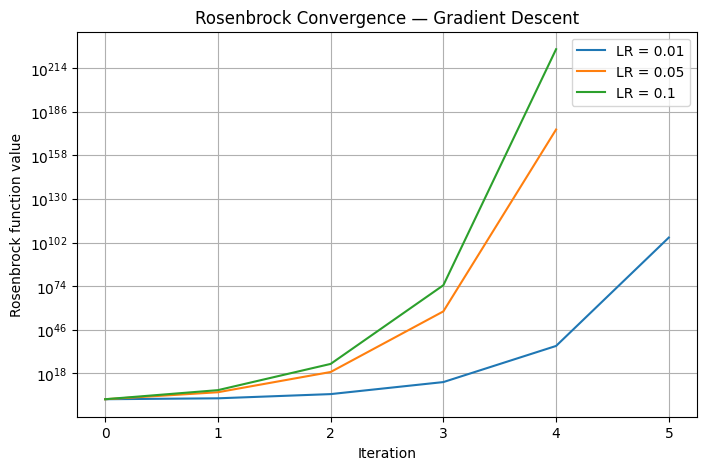

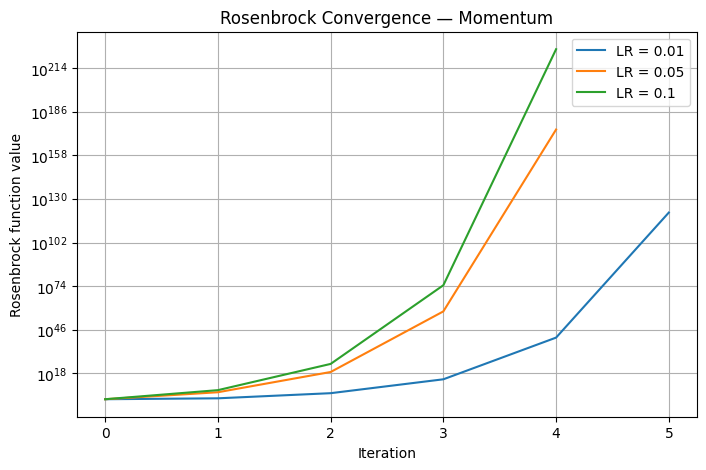

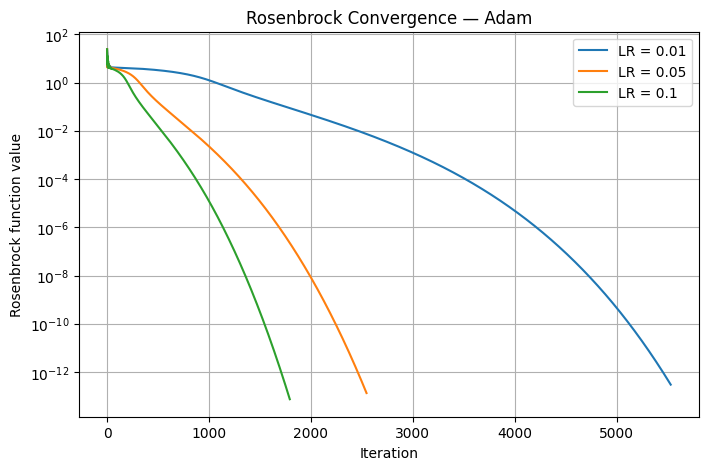

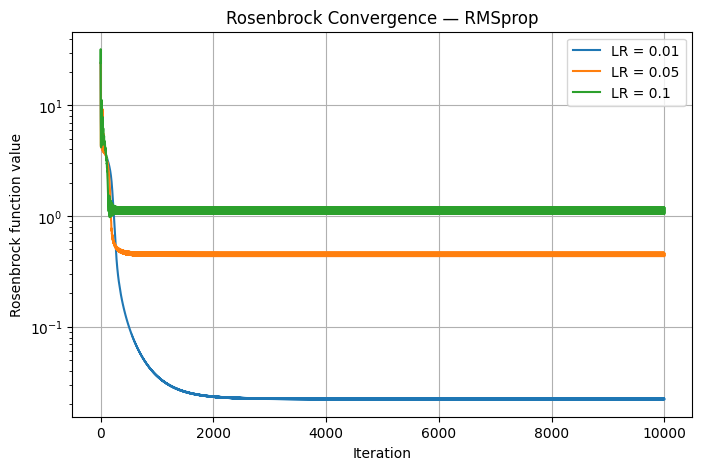

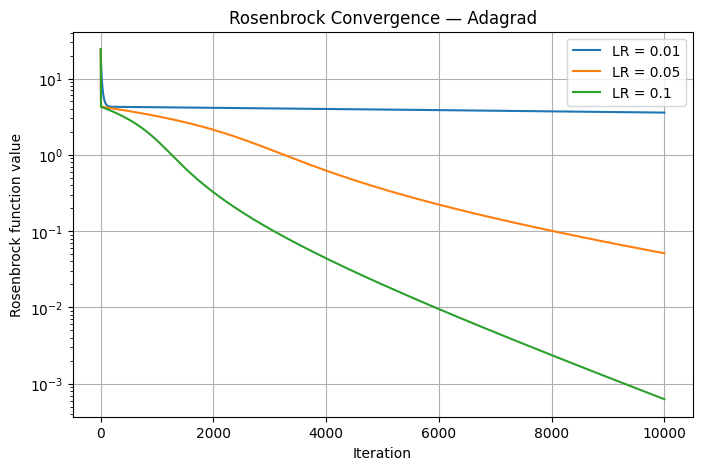

In [10]:

for optimizer_name in optimizers:
    plt.figure(figsize=(8, 5))

    for lr in learning_rates:
        history = rosenbrock_results[optimizer_name][lr]["history"]

        # Avoid problems with log scale if numerical noise produces zero.
        safe_history = np.maximum(history, 1e-16)

        plt.plot(
            safe_history,
            label=f"LR = {lr}"
        )

    plt.yscale("log")
    plt.xlabel("Iteration")
    plt.ylabel("Rosenbrock function value")
    plt.title(f"Rosenbrock Convergence — {optimizer_name}")
    plt.legend()
    plt.grid(True)
    plt.show()



## 11. Ackley Results

For the simplified 1D Ackley function, the expected global optimum is:

$$
x=0,\qquad f(x)=0
$$

Therefore, the closer the final `x` is to 0 and the closer `f(x)` is to 0, the better the result.


In [11]:

print_results(ackley_results, "Ackley Optimization Results")



Ackley Optimization Results

Gradient Descent
  LR=0.01 | solution=[1.974452] | f(x)=6.55964538e+00 | iterations=5 | time=0.000343s | status=converged
  LR=0.05 | solution=[0.315579] | f(x)=3.27158972e+00 | iterations=10000 | time=0.759391s | status=max_iter
  LR=0.1  | solution=[0.947334] | f(x)=3.59554150e+00 | iterations=10000 | time=0.685959s | status=max_iter

Momentum
  LR=0.01 | solution=[1.974452] | f(x)=6.55964538e+00 | iterations=252 | time=0.014630s | status=converged
  LR=0.05 | solution=[19.88106] | f(x)=2.02607691e+01 | iterations=10000 | time=0.865630s | status=max_iter
  LR=0.1  | solution=[5.334521] | f(x)=1.52342108e+01 | iterations=10000 | time=0.670696s | status=max_iter

Adam
  LR=0.01 | solution=[1.974452] | f(x)=6.55964538e+00 | iterations=238 | time=0.010092s | status=converged
  LR=0.05 | solution=[1.974452] | f(x)=6.55964538e+00 | iterations=247 | time=0.010117s | status=converged
  LR=0.1  | solution=[1.974452] | f(x)=6.55964538e+00 | iterations=274 | time=0


## 12. Ackley Convergence Plots


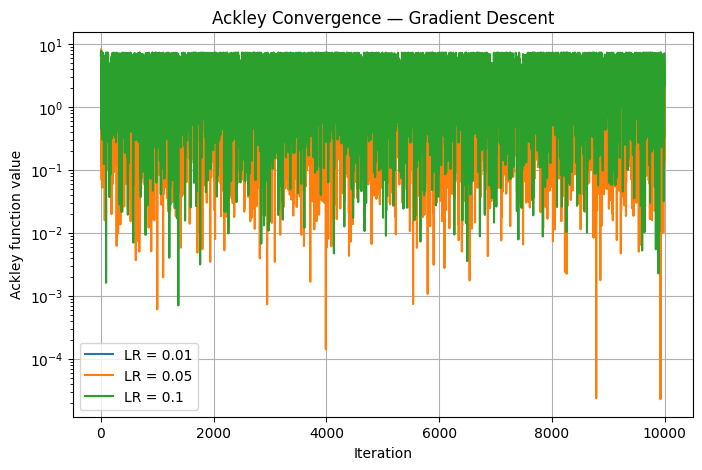

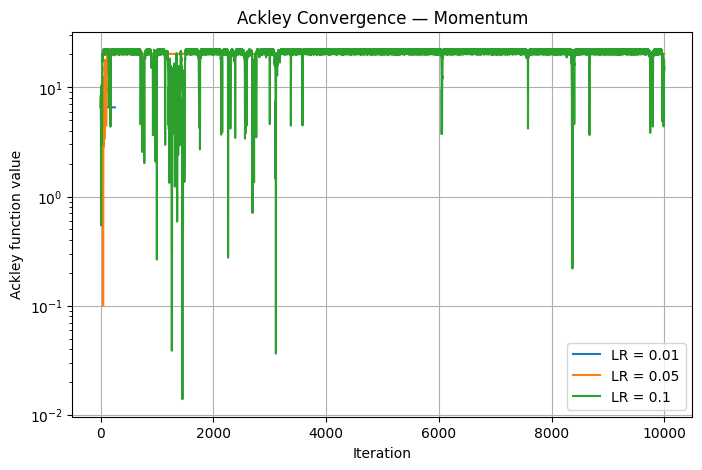

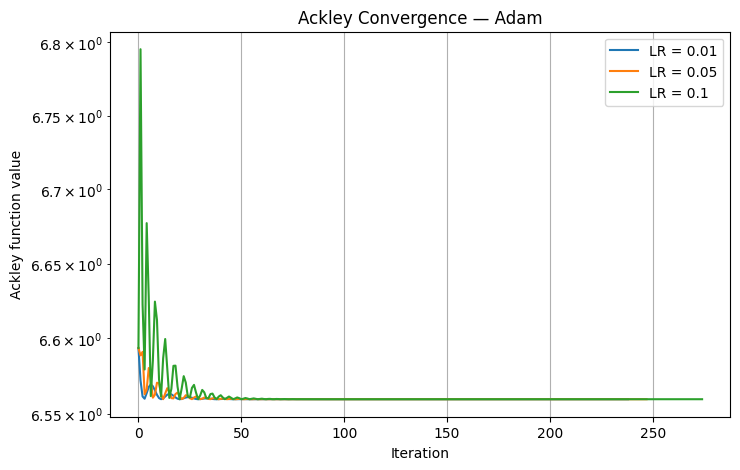

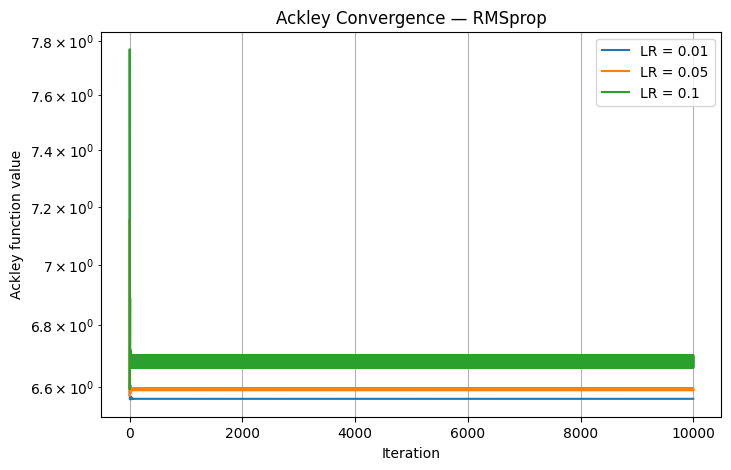

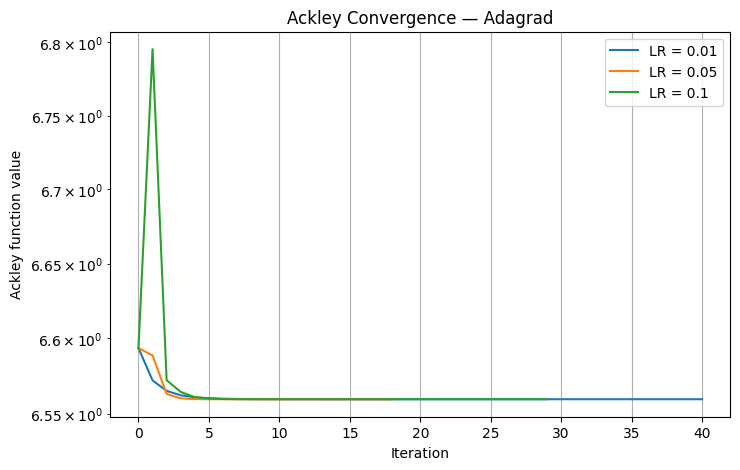

In [12]:

for optimizer_name in optimizers:
    plt.figure(figsize=(8, 5))

    for lr in learning_rates:
        history = ackley_results[optimizer_name][lr]["history"]

        safe_history = np.maximum(history, 1e-16)

        plt.plot(
            safe_history,
            label=f"LR = {lr}"
        )

    plt.yscale("log")
    plt.xlabel("Iteration")
    plt.ylabel("Ackley function value")
    plt.title(f"Ackley Convergence — {optimizer_name}")
    plt.legend()
    plt.grid(True)
    plt.show()



## 13. Compare Learning Rates

The learning rate controls how large each update is.

- **0.01:** smaller updates; usually more stable but may require more iterations.
- **0.05:** larger updates; can converge faster when the problem is well behaved.
- **0.1:** even larger updates; may be faster, but can also overshoot or become unstable.

The actual result should be determined from the experimental output rather than assuming that one learning rate is always best.


In [13]:
def best_results(results):
    rows = []

    for optimizer_name in results:
        for lr in learning_rates:
            r = results[optimizer_name][lr]

            rows.append({
                "Optimizer": optimizer_name,
                "Learning Rate": lr,
                "Final Value": r["value"],
                "Iterations": r["iterations"],
                "Time (s)": r["time"],
                "Status": r["status"],
                "Solution": np.round(r["x"], 6)
            })

    return rows


print("Rosenbrock:")
for row in best_results(rosenbrock_results):
    print(row)

print("\nAckley:")
for row in best_results(ackley_results):
    print(row)


Rosenbrock:
{'Optimizer': 'Gradient Descent', 'Learning Rate': 0.01, 'Final Value': np.float64(inf), 'Iterations': 6, 'Time (s)': 0.0007493749999980537, 'Status': 'diverged', 'Solution': array([1.11635695e+78, 8.54132780e+51])}
{'Optimizer': 'Gradient Descent', 'Learning Rate': 0.05, 'Final Value': np.float64(inf), 'Iterations': 5, 'Time (s)': 0.0004133669999646372, 'Status': 'diverged', 'Solution': array([6.52442774e+130, 2.19958941e+087])}
{'Optimizer': 'Gradient Descent', 'Learning Rate': 0.1, 'Final Value': np.float64(inf), 'Iterations': 5, 'Time (s)': 0.0007100130000026184, 'Status': 'diverged', 'Solution': array([6.49033039e+169, 2.76164513e+113])}
{'Optimizer': 'Momentum', 'Learning Rate': 0.01, 'Final Value': np.float64(inf), 'Iterations': 6, 'Time (s)': 0.00030917700001964477, 'Status': 'diverged', 'Solution': array([1.25195462e+90, 9.21967740e+59])}
{'Optimizer': 'Momentum', 'Learning Rate': 0.05, 'Final Value': np.float64(inf), 'Iterations': 5, 'Time (s)': 0.0003418000000010


## 14. Visual Comparison of Optimizers

For a fixed learning rate, we can directly compare all five optimizers.

This is useful because the assignment specifically asks for the optimal solution obtained by the different GD algorithms for a fixed learning rate.


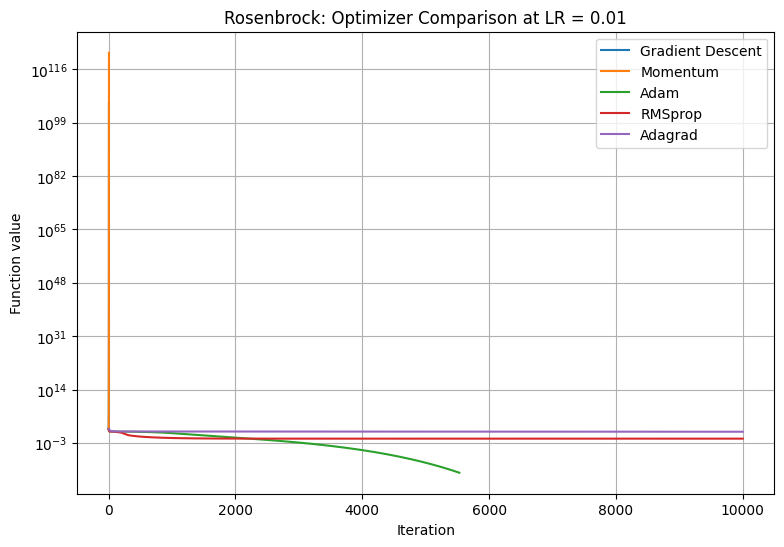

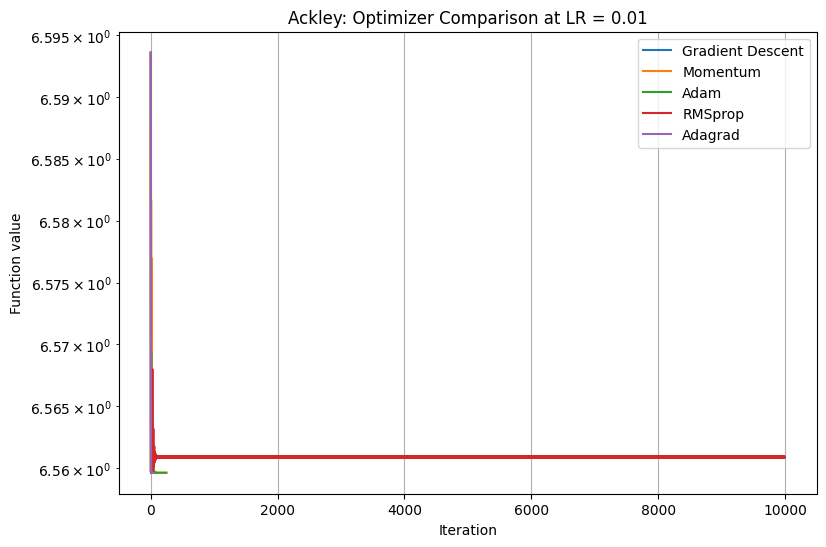

In [14]:

fixed_lr = 0.01

plt.figure(figsize=(9, 6))

for optimizer_name in optimizers:
    history = rosenbrock_results[optimizer_name][fixed_lr]["history"]
    plt.plot(
        np.maximum(history, 1e-16),
        label=optimizer_name
    )

plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Function value")
plt.title(f"Rosenbrock: Optimizer Comparison at LR = {fixed_lr}")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(9, 6))

for optimizer_name in optimizers:
    history = ackley_results[optimizer_name][fixed_lr]["history"]
    plt.plot(
        np.maximum(history, 1e-16),
        label=optimizer_name
    )

plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Function value")
plt.title(f"Ackley: Optimizer Comparison at LR = {fixed_lr}")
plt.legend()
plt.grid(True)
plt.show()


In [15]:

def summarize_best(results, function_name):
    finite_rows = []

    for optimizer_name in results:
        for lr in learning_rates:
            r = results[optimizer_name][lr]
            if np.isfinite(r["value"]):
                finite_rows.append(
                    (r["value"], optimizer_name, lr, r)
                )

    finite_rows.sort(key=lambda item: item[0])

    print(f"\nBest finite results for {function_name}")
    print("-" * 45)

    if not finite_rows:
        print("No finite result was obtained.")
        return

    for value, optimizer_name, lr, r in finite_rows[:5]:
        print(
            f"{optimizer_name:20s} | "
            f"LR={lr:<4} | "
            f"x={np.round(r['x'], 8)} | "
            f"f(x)={value:.8e} | "
            f"status={r['status']}"
        )


summarize_best(rosenbrock_results, "Rosenbrock")
summarize_best(ackley_results, "Ackley")



Best finite results for Rosenbrock
---------------------------------------------
Adam                 | LR=0.1  | x=[0.99999972 0.99999944] | f(x)=7.69606943e-14 | status=converged
Adam                 | LR=0.05 | x=[0.99999963 0.99999925] | f(x)=1.38549571e-13 | status=converged
Adam                 | LR=0.01 | x=[0.99999944 0.99999889] | f(x)=3.09653295e-13 | status=converged
Adagrad              | LR=0.1  | x=[0.97497371 0.9504954 ] | f(x)=6.26928713e-04 | status=max_iter
RMSprop              | LR=0.01 | x=[0.990144   0.96553369] | f(x)=2.21537159e-02 | status=max_iter

Best finite results for Ackley
---------------------------------------------
Gradient Descent     | LR=0.05 | x=[0.31557881] | f(x)=3.27158972e+00 | status=max_iter
Gradient Descent     | LR=0.1  | x=[0.94733432] | f(x)=3.59554150e+00 | status=max_iter
Gradient Descent     | LR=0.01 | x=[1.97445199] | f(x)=6.55964538e+00 | status=converged
Adagrad              | LR=0.05 | x=[1.97445199] | f(x)=6.55964538e+00 | statu